# 3) Capacitor Impedance Simulation

This notebook generates controlled impedance datasets for an ideal capacitor
across a logarithmic frequency range.

Goals:
- Generate a frequency vector
- Compute impedance $Z_C = 1 / (j ω C)$
- Add optional Gaussian noise
- Visualise real/imag/magnitude/phase
- Export dataset to `data/simulated/`


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.simulation.capacitor import simulate_capacitor

In [2]:
# Simulation Parameters
C = 1e-6  # 1 µF
f_min = 1
f_max = 1e5
num_points = 300

frequencies = np.logspace(np.log10(f_min), np.log10(f_max), num_points)
noise_level = 0.05  # small noise on imaginary part

Z = simulate_capacitor(C, frequencies, noise_level=noise_level)

real_Z = Z.real
imag_Z = Z.imag
mag_Z = np.abs(Z)
phase_Z = np.angle(Z)


# Visualisations

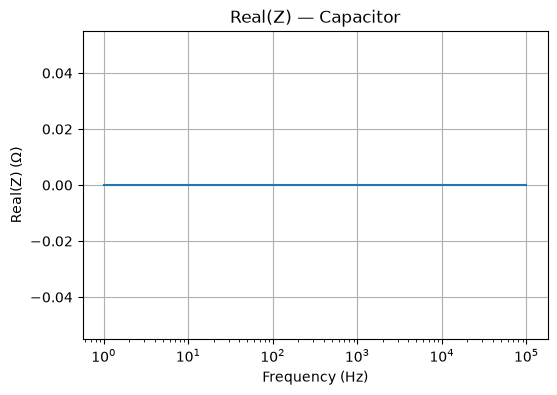

In [3]:
# Real part
plt.figure(figsize=(6,4))
plt.semilogx(frequencies, real_Z)
plt.title("Real(Z) — Capacitor")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Real(Z) (Ω)")
plt.grid(True)
plt.show()


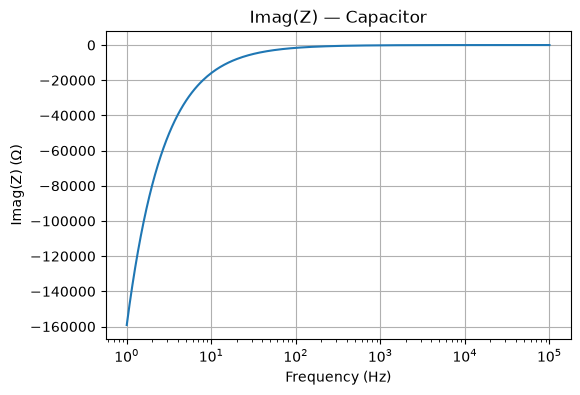

In [4]:
# Imaginary part
plt.figure(figsize=(6,4))
plt.semilogx(frequencies, imag_Z)
plt.title("Imag(Z) — Capacitor")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Imag(Z) (Ω)")
plt.grid(True)
plt.show()

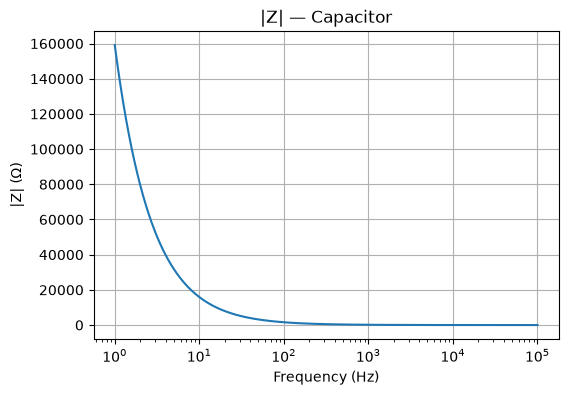

In [5]:
# Magnitude
plt.figure(figsize=(6,4))
plt.semilogx(frequencies, mag_Z)
plt.title("|Z| — Capacitor")
plt.xlabel("Frequency (Hz)")
plt.ylabel("|Z| (Ω)")
plt.grid(True)
plt.show()

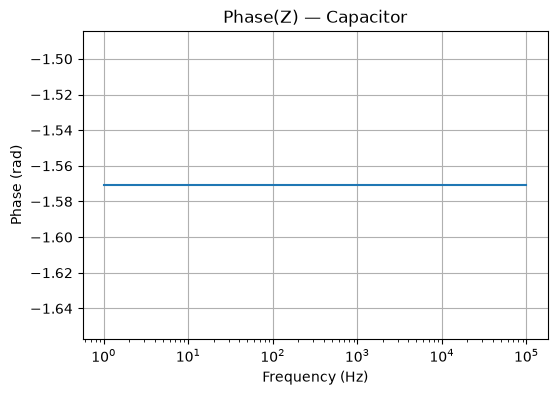

In [6]:
# Phase
plt.figure(figsize=(6,4))
plt.semilogx(frequencies, phase_Z)
plt.title("Phase(Z) — Capacitor")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Phase (rad)")
plt.grid(True)
plt.show()

# Export Dataset

In [7]:
df = pd.DataFrame({
    "frequency": frequencies,
    "real": real_Z,
    "imag": imag_Z,
    "magnitude": mag_Z,
    "phase_rad": phase_Z
})

output_path = "../data/simulated/capacitor_C1uF.csv"
df.to_csv(output_path, index=False)

output_path


'../data/simulated/capacitor_C1uF.csv'

# Summary

This notebook generated a simulated impedance dataset for an ideal capacitor.
The dataset was saved in `data/simulated/capacitor_C1uF.csv`.